# 05 · Walk-forward strategy audit

Can a fixed reversal rule survive execution delays, costs, and a chronological holdout?

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63

## Timing and accounting

Parameters were specified before inspecting initial results. Training (through 2021), validation
(2022–2023) and holdout (2024 onward) are chronological. Estimators update online, using only past
data; no model is chosen by holdout profit. Each scored segment starts flat and pays terminal
liquidation costs. Warm-up data can inform later states but does not carry a position across splits.

The code observes z and beta after close t, executes at close t+1, and first earns the return
ending at t+2. Costs are charged at the beginning of that first holding interval. Daily target
weights are fractions of pre-trade NAV; the simulator charges turnover against **drifted** holdings,
not just changes in target weights. Both legs contribute to P&L and short carry. Borrow runs on
calendar days, including weekends. Cash earns zero. QQQ total returns already include distributions.

The 10-session holding cap and exits act on decision dates; execution is delayed. Gap losses can
exceed a signal-based stop. There is no claim of a guaranteed maximum loss or institutional fill quality.

,sessions,total_return,cagr,annual_vol,sharpe_zero_cash,max_drawdown,active_fraction,annual_turnover,cost_drag_sum
train,673.0000,-0.1884,-0.0752,0.0617,-1.2359,-0.2102,0.3016,5.7426,0.0159
validation,501.0000,-0.0145,-0.0073,0.0347,-0.1942,-0.0372,0.1876,4.6104,0.0094
holdout,716.0000,-0.1009,-0.0367,0.0556,-0.6457,-0.1230,0.2277,5.9950,0.0179
holdout_same_signal_unhedged,716.0000,-0.1131,-0.0414,0.0625,-0.6444,-0.1317,0.2277,3.0707,0.0121


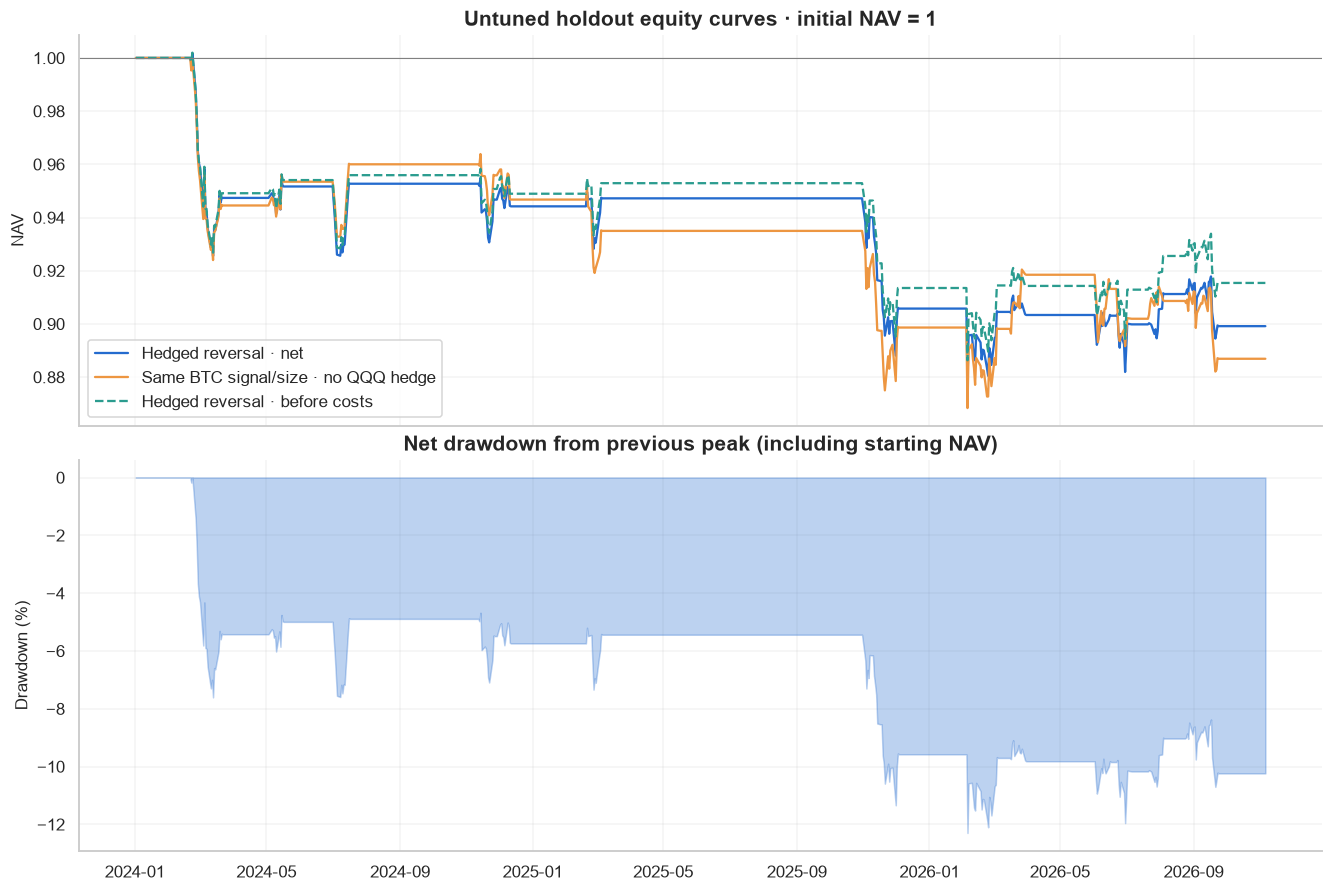

In [2]:
from btc_nasdaq.strategy import performance
from btc_nasdaq.diagnostics import block_bootstrap
stats = pd.read_csv(ROOT / "reports/tables/strategy_performance.csv", index_col=0)
display(stats)
holdout = run_period(c, HOLDOUT)
unhedged = run_period(c, HOLDOUT, unhedged=True)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
holdout.equity.plot(ax=axes[0], label="Hedged reversal · net")
unhedged.equity.plot(ax=axes[0], label="Same BTC signal/size · no QQQ hedge")
((1 + holdout.gross_return).cumprod()).plot(ax=axes[0], label="Hedged reversal · before costs", linestyle="--")
axes[0].axhline(1, color="gray", lw=.7)
axes[0].set(title="Untuned holdout equity curves · initial NAV = 1", ylabel="NAV")
axes[0].legend()
axes[1].fill_between(holdout.index, holdout.drawdown*100, 0, alpha=.3, color=PALETTE[0])
axes[1].set(title="Net drawdown from previous peak (including starting NAV)", ylabel="Drawdown (%)")
save_figure(fig, ROOT, "05_holdout_performance")
plt.show()

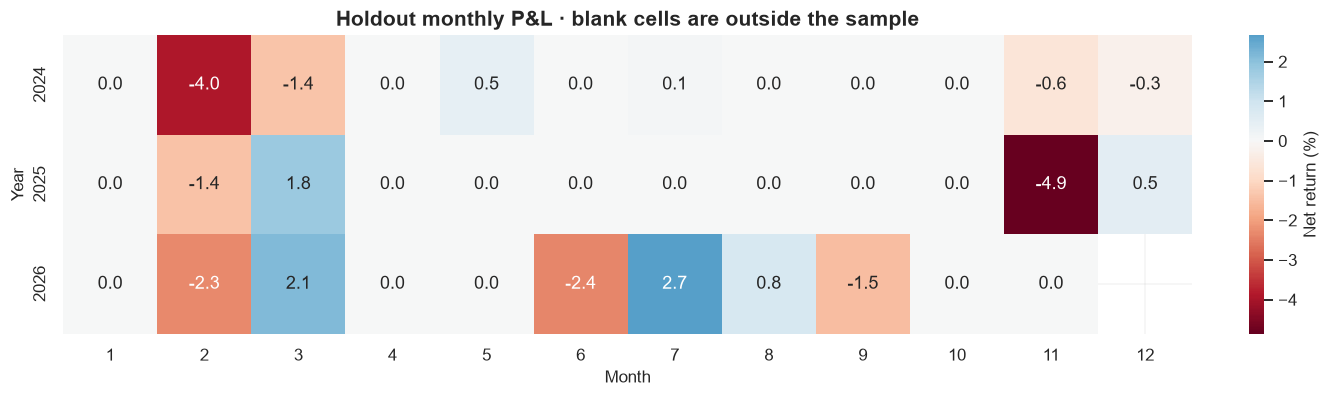

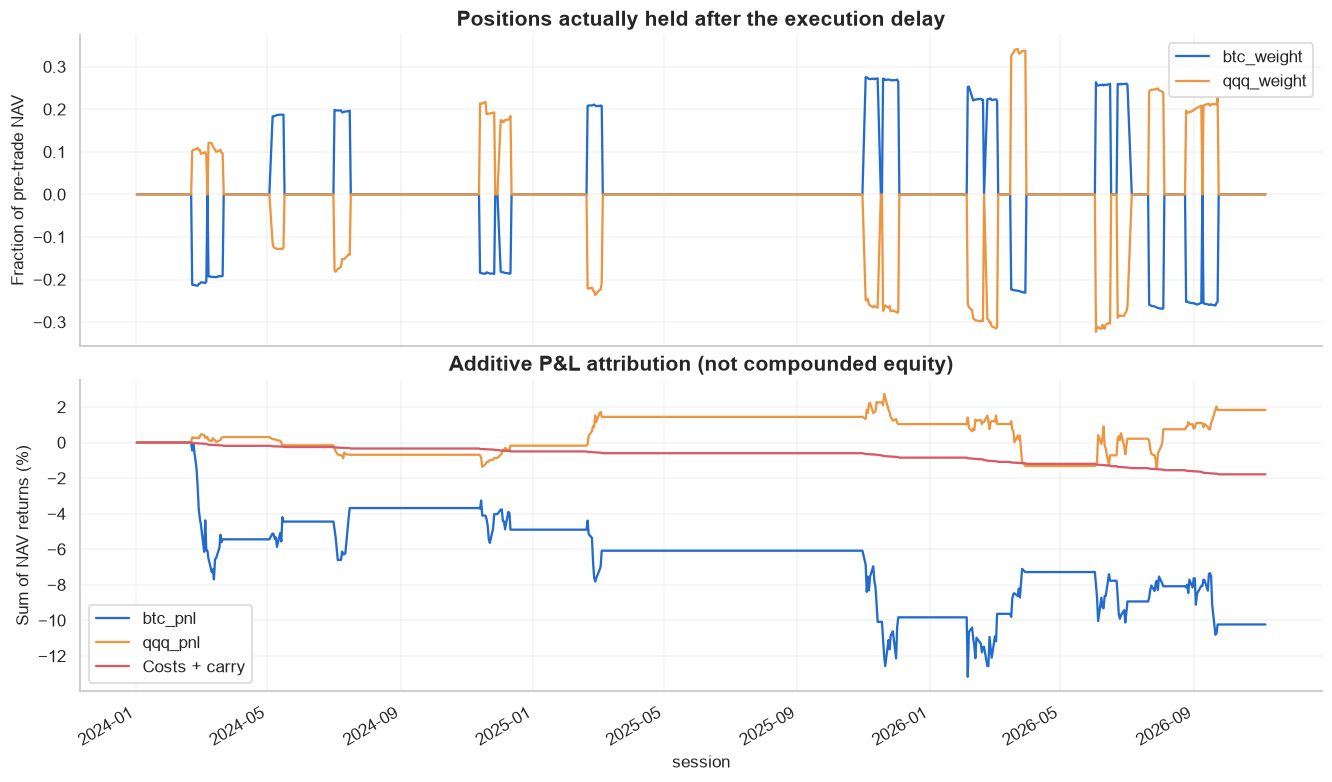

In [3]:
monthly = holdout.net_return.groupby([holdout.index.year, holdout.index.month]).apply(lambda x: (1+x).prod()-1).unstack()
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(monthly*100, cmap="RdBu", center=0, annot=True, fmt=".1f", ax=ax, cbar_kws={"label": "Net return (%)"})
ax.set(title="Holdout monthly P&L · blank cells are outside the sample", xlabel="Month", ylabel="Year")
plt.show()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
holdout[["btc_weight", "qqq_weight"]].plot(ax=axes[0])
axes[0].set(title="Positions actually held after the execution delay", ylabel="Fraction of pre-trade NAV")
holdout[["btc_pnl", "qqq_pnl"]].cumsum().mul(100).plot(ax=axes[1])
(-(holdout.trade_cost+holdout.carry).cumsum()*100).plot(ax=axes[1], label="Costs + carry", color=PALETTE[4])
axes[1].set(title="Additive P&L attribution (not compounded equity)", ylabel="Sum of NAV returns (%)")
axes[1].legend()
plt.show()

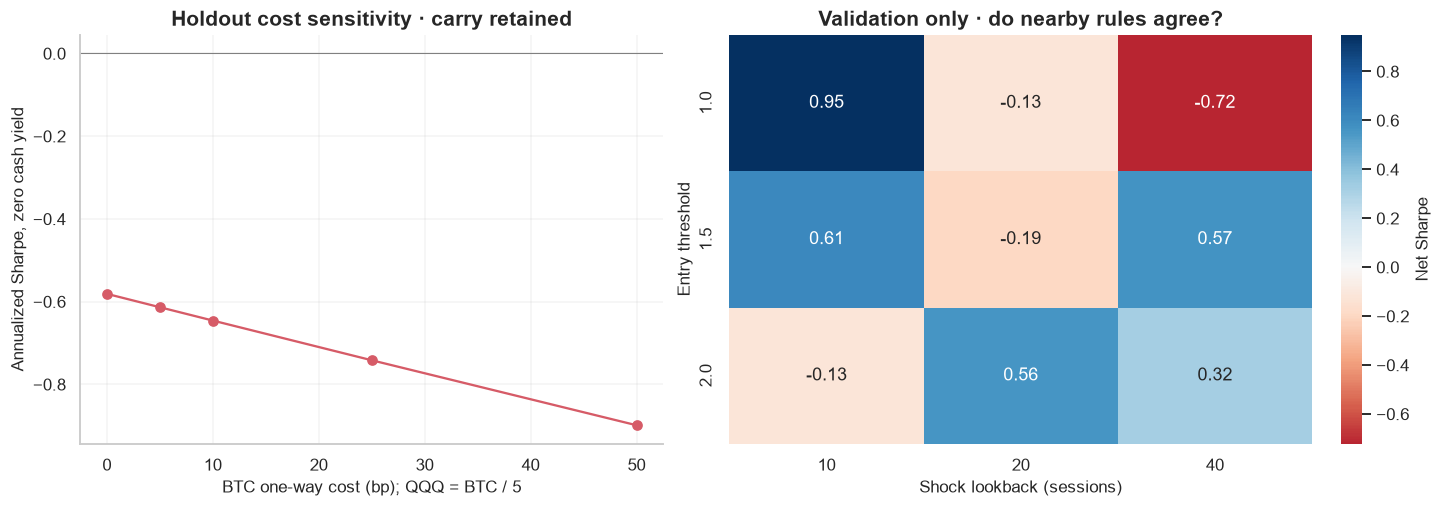

,btc_bps,qqq_bps,total_return,sharpe_zero_cash,annual_turnover
0,0.0000,0.0000,-0.0914,-0.5811,5.9951
1,5.0000,1.0000,-0.0962,-0.6135,5.9950
2,10.0000,2.0000,-0.1009,-0.6457,5.9950
3,25.0000,5.0000,-0.1148,-0.7417,5.9948
4,50.0000,10.0000,-0.1376,-0.8988,5.9945


In [4]:
costs = pd.read_csv(ROOT / "reports/tables/cost_sensitivity.csv")
sensitivity = pd.read_csv(ROOT / "reports/tables/validation_sensitivity.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(costs.btc_bps, costs.sharpe_zero_cash, "o-", color=PALETTE[4])
axes[0].axhline(0, color="gray", lw=.7)
axes[0].set(title="Holdout cost sensitivity · carry retained", xlabel="BTC one-way cost (bp); QQQ = BTC / 5", ylabel="Annualized Sharpe, zero cash yield")
sns.heatmap(sensitivity.pivot(index="entry_z", columns="lookback", values="sharpe_zero_cash"), annot=True,
            fmt=".2f", center=0, cmap="RdBu", ax=axes[1], cbar_kws={"label": "Net Sharpe"})
axes[1].set(title="Validation only · do nearby rules agree?", xlabel="Shock lookback (sessions)", ylabel="Entry threshold")
save_figure(fig, ROOT, "05_cost_and_parameter_sensitivity")
plt.show()
display(costs[["btc_bps", "qqq_bps", "total_return", "sharpe_zero_cash", "annual_turnover"]])

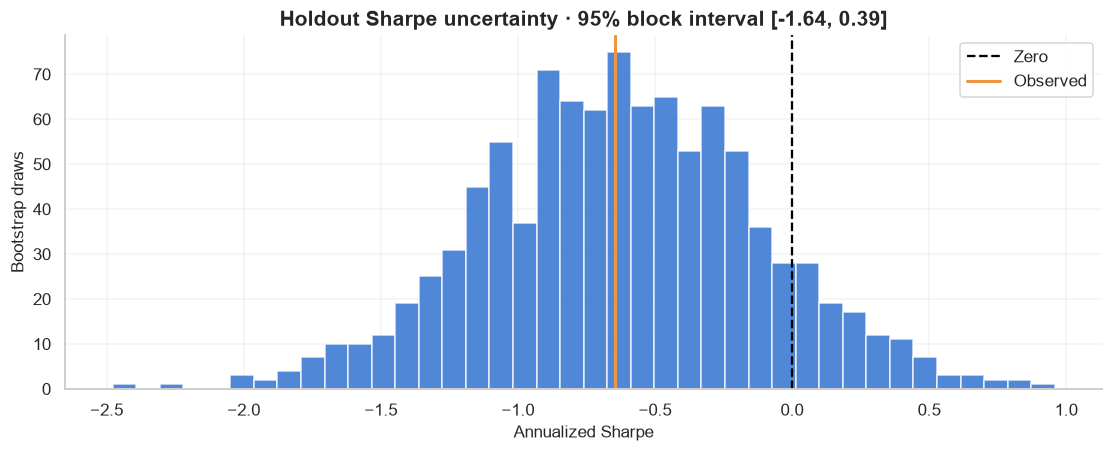

**Observed holdout:** net return -10.1%; Sharpe -0.65; max drawdown -12.3%. The interval is conditional on this sample and strategy, not a forward guarantee.

In [5]:
def sharpe(a):
    return a.mean()/a.std(ddof=1)*np.sqrt(252) if a.std() else np.nan
draws = block_bootstrap(holdout.net_return.to_numpy(), sharpe, samples=1000, block=10, seed=42)
interval = np.nanquantile(draws, [.025, .975])
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(draws, bins=40, color=PALETTE[0], alpha=.8)
ax.axvline(0, color="black", linestyle="--", label="Zero")
ax.axvline(sharpe(holdout.net_return.to_numpy()), color=PALETTE[1], lw=2, label="Observed")
ax.set(title=f"Holdout Sharpe uncertainty · 95% block interval [{interval[0]:.2f}, {interval[1]:.2f}]", xlabel="Annualized Sharpe", ylabel="Bootstrap draws")
ax.legend()
plt.show()
display(Markdown(f"**Observed holdout:** net return {performance(holdout)['total_return']:.1%}; "
                 f"Sharpe {performance(holdout)['sharpe_zero_cash']:.2f}; "
                 f"max drawdown {performance(holdout)['max_drawdown']:.1%}. "
                 "The interval is conditional on this sample and strategy, not a forward guarantee."))

**Decision:** use this pass to accept or reject the specific rule, not the entire idea of BTC-specific
mean reversion. Compare hedged and unhedged versions to understand whether the hedge changes the
intended alpha. The unhedged comparator keeps the same BTC size and therefore has different gross
exposure; it is an attribution comparison, not an equal-risk contest. Stress borrowing and fills before
claiming implementability. Repeated tuning after inspecting these results requires new evaluation data.

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.